In [ ]:
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'heliomind-integrated').is_dir())
(ROOT/'data/processed/Anomaly').mkdir(parents=True,exist_ok=True)


- **Load Nasa & Meteo DataSet**

In [ ]:
import os
import pandas as pd
from pvlib.iotools import get_nasa_power

def fetch_and_save_nasa_weather(lat: float, lon: float, start_date: str, end_date: str, output_path: str = "data/raw/nasa_weather_raw.csv"):
    print(f"[*] Fetching data for coordinates (Lat: {lat}, Lon: {lon}) from the period {start_date} to {end_date}...")
    
    data, metadata = get_nasa_power(
        latitude=lat,
        longitude=lon,
        start=start_date,
        end=end_date,
        parameters=['ALLSKY_SFC_SW_DWN', 'T2M', 'WS10M'],
        community='RE'
    )
    
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    
    data.to_csv(output_path)    
    return data, metadata

if __name__ == "__main__":
    LATITUDE = 30.7885
    LONGITUDE = 31.0021
    START_DATE = "2023-01-01"
    END_DATE = "2023-12-31"
    
    fetch_and_save_nasa_weather(LATITUDE, LONGITUDE, START_DATE, END_DATE)

In [12]:
import os
import requests
import pandas as pd

def fetch_openmeteo_weather(lat: float, lon: float, start_date: str, end_date: str, output_path: str = "data/raw/open_meteo_raw.csv"):
    print(f"[*] Fetching Open-Meteo data for coordinates (Lat: {lat}, Lon: {lon})...")
    
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": "temperature_2m,relative_humidity_2m,direct_normal_irradiance,diffuse_radiation,shortwave_radiation,wind_speed_10m",
        "timezone": "UTC"
    }
    
    response = requests.get(url, params=params)
    if response.status_code != 200:
        raise Exception(f"Failed to connect to API: {response.text}")
        
    data = response.json()
    hourly_data = data.get("hourly", {})
    
    df = pd.DataFrame(hourly_data)
    df['time'] = pd.to_datetime(df['time'])
    df.set_index('time', inplace=True)
    
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    
    df.to_csv(output_path)    
    return df

if __name__ == "__main__":
    LATITUDE = 30.7885
    LONGITUDE = 31.0021
    START_DATE = "2023-01-01"
    END_DATE = "2023-12-31"
    
    fetch_openmeteo_weather(LATITUDE, LONGITUDE, START_DATE, END_DATE)

[*] Fetching Open-Meteo data for coordinates (Lat: 30.7885, Lon: 31.0021)...


# Solar Energy Project - Audit & EDA

This notebook provides a simple, reproducible EDA for all raw and processed datasets.

## Analysis goals
1. Verify file paths and dataset structure.
2. Check missing values, duplicates, and data types.
3. Identify useful date/time and numeric columns.
4. Compare raw sources with processed files.
5. Record decisions that will guide cleaning and modeling.

## How to use
Run the notebook from top to bottom. The same audit and summary functions are reused for every CSV, so the structure stays consistent and the code remains easy to maintain.

In [3]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

PROJECT_ROOT = ROOT
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

print("Project root:", PROJECT_ROOT)
print("Raw data folder:", RAW_DIR)
print("Processed data folder:", PROCESSED_DIR)

Project root: f:\Abdelrahman1\ME\programming\SIC\Project3.2
Raw data folder: f:\Abdelrahman1\ME\programming\SIC\Project3.2\data\raw
Processed data folder: f:\Abdelrahman1\ME\programming\SIC\Project3.2\data\processed


## Dataset inventory

The inventory below automatically includes every CSV file under `data/raw` and `data/processed`.

In [4]:
csv_files = sorted(list(RAW_DIR.rglob("*.csv")) + list(PROCESSED_DIR.rglob("*.csv")))

inventory = []
for file in csv_files:
    inventory.append({
        "Group": "raw" if RAW_DIR in file.parents else "processed",
        "File": file.relative_to(PROJECT_ROOT).as_posix(),
    })

inventory_df = pd.DataFrame(inventory)
display(inventory_df)

,Group,File
0,processed,data/processed/Anomaly/anomaly_features_final.csv
1,processed,data/processed/Anomaly/kaggle_anomaly_data.csv
2,processed,data/processed/Anomaly/kaggle_merged_clean.csv
3,processed,data/processed/Forecast/forecast_dkasc_clean.csv
4,processed,data/processed/Forecast/forecast_features_fina...
5,raw,data/raw/Alice_Springs_2025.csv
6,raw,data/raw/kaggle/Plant_1_Generation_Data.csv
7,raw,data/raw/kaggle/Plant_1_Weather_Sensor_Data.csv
8,raw,data/raw/kaggle/Plant_2_Generation_Data.csv
9,raw,data/raw/kaggle/Plant_2_Weather_Sensor_Data.csv


## 1. Dataset audit

For each file, this section reports:
- Row and column counts.
- Duplicate rows.
- Missing-value percentage.
- Data types.
- Numeric ranges for the first useful variables.

```python
"""Audit helpers"""
```


In [5]:
def audit_csv(file_path):
    read_options = {}
    if "Alice_Springs" in file_path.name:
        read_options["on_bad_lines"] = "skip"

    df = pd.read_csv(file_path, low_memory=False, **read_options)

    summary = {
        "Dataset": file_path.relative_to(PROJECT_ROOT).as_posix(),
        "Rows": len(df),
        "Columns": df.shape[1],
        "Duplicate rows": int(df.duplicated().sum()),
        "Missing cells": int(df.isna().sum().sum()),
        "Missing %": round(df.isna().mean().mean() * 100, 2),
    }
    return df, summary

loaded = {}
audit_rows = []

for file_path in csv_files:
    try:
        df, summary = audit_csv(file_path)
        loaded[file_path.name] = df
        audit_rows.append(summary)
    except Exception as error:
        audit_rows.append({
            "Dataset": file_path.relative_to(PROJECT_ROOT).as_posix(),
            "Rows": "ERROR",
            "Columns": "ERROR",
            "Duplicate rows": str(error)[:120],
            "Missing cells": None,
            "Missing %": None,
        })

audit_df = pd.DataFrame(audit_rows)
display(audit_df)

,Dataset,Rows,Columns,Duplicate rows,Missing cells,Missing %
0,data/processed/Anomaly/anomaly_features_final.csv,64892,14,0,0,0.0
1,data/processed/Anomaly/kaggle_anomaly_data.csv,64892,12,0,0,0.0
2,data/processed/Anomaly/kaggle_merged_clean.csv,136472,11,0,0,0.0
3,data/processed/Forecast/forecast_dkasc_clean.csv,98146,5,0,0,0.0
4,data/processed/Forecast/forecast_features_fina...,98146,13,0,0,0.0
5,data/raw/Alice_Springs_2025.csv,105391,210,0,2500580,11.3
6,data/raw/kaggle/Plant_1_Generation_Data.csv,68778,7,0,0,0.0
7,data/raw/kaggle/Plant_1_Weather_Sensor_Data.csv,3182,6,0,0,0.0
8,data/raw/kaggle/Plant_2_Generation_Data.csv,67698,7,0,0,0.0
9,data/raw/kaggle/Plant_2_Weather_Sensor_Data.csv,3259,6,0,0,0.0


## 2. Missing-value details

Review the columns with missing values instead of only the total missing percentage.

In [6]:
missing_details = []

for file_name, df in loaded.items():
    missing = df.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    for column, count in missing.items():
        missing_details.append({
            "Dataset": file_name,
            "Column": column,
            "Missing count": int(count),
            "Missing %": round(count / len(df) * 100, 2),
        })

missing_df = pd.DataFrame(missing_details)
if missing_df.empty:
    print("No missing values were found in the loaded datasets.")
else:
    display(missing_df.sort_values(["Missing %", "Dataset"], ascending=[False, True]))

,Dataset,Column,Missing count,Missing %
0,Alice_Springs_2025.csv,205_Archived_DKA_M15_BPhase_UMG_QCells_Active_...,105391,100.00
1,Alice_Springs_2025.csv,205_Archived_DKA_M15_BPhase_UMG_QCells_Current...,105391,100.00
2,Alice_Springs_2025.csv,205_Archived_DKA_M15_BPhase_UMG_QCells_Active_...,105391,100.00
3,Alice_Springs_2025.csv,57_DKA_M16_A_Phase_Performance_Ratio,105391,100.00
4,Alice_Springs_2025.csv,54_DKA_M15_C_Phase_Active_Energy_Delivered_Rec...,105391,100.00
...,...,...,...,...
204,Alice_Springs_2025.csv,242_DKA_Totals_Grid_Reactive_Power,79,0.07
205,Alice_Springs_2025.csv,242_DKA_Totals_Grid_Apparent_Power,79,0.07
206,Alice_Springs_2025.csv,241_DKA_Totals_PV_Reactive_Power,78,0.07
207,Alice_Springs_2025.csv,241_DKA_Totals_PV_Active_Power,78,0.07


## 3. Column definitions

These tables give a short description of each column in the three regular datasets.

### NASA weather

| Column | Definition |
|---|---|
| Unnamed: 0 | Observation timestamp in the raw CSV. |
| ghi | Global Horizontal Irradiance. |
| temp_air | Ambient air temperature. |
| wind_speed | Wind speed. |

### Open-Meteo

| Column | Definition |
|---|---|
| time | Observation timestamp, hourly. |
| temperature_2m | Air temperature 2 meters above ground. |
| relative_humidity_2m | Relative humidity 2 meters above ground. |
| direct_normal_irradiance | Direct solar radiation perpendicular to the sun. |
| diffuse_radiation | Solar radiation received indirectly from the sky. |
| shortwave_radiation | Incoming shortwave solar radiation. |
| wind_speed_10m | Wind speed 10 meters above ground. |

### Kaggle merged clean data

| Column | Definition |
|---|---|
| DATE_TIME | Generation and weather observation timestamp. |
| PLANT_ID | Solar plant identifier. |
| SOURCE_KEY | Inverter/source identifier. |
| DC_POWER | Direct-current generated power. |
| AC_POWER | Alternating-current generated power. |
| DAILY_YIELD | Energy generated during the current day. |
| TOTAL_YIELD | Cumulative energy generated by the plant. |
| SOURCE_KEY_weather | Weather sensor/source identifier. |
| AMBIENT_TEMPERATURE | Temperature around the solar plant. |
| MODULE_TEMPERATURE | Temperature of the solar modules. |
| IRRADIATION | Solar irradiation at the observation time. |

In [8]:
regular_datasets = {
    "nasa_weather_raw.csv": RAW_DIR / "nasa_weather_raw.csv",
    "open_meteo_raw.csv": RAW_DIR / "open_meteo_raw.csv",
    "kaggle_merged_clean.csv": PROCESSED_DIR / "Anomaly/kaggle_merged_clean.csv",
}

regular_data = {}

for name, path in regular_datasets.items():
    df = pd.read_csv(path, low_memory=False)

    if name == "nasa_weather_raw.csv" and "ghi" in df.columns:
        df["ghi"] = pd.to_numeric(df["ghi"], errors="coerce")

    regular_data[name] = df

    print(f"\n{name}")

    numeric_df = df.select_dtypes(include="number")
    if not numeric_df.empty:
        display(numeric_df.describe().T.round(3))

    categorical_df = df.select_dtypes(include=["object", "string"])
    if not categorical_df.empty:
        categorical_summary = pd.DataFrame({
            "Column": categorical_df.columns,
            "Unique values": [df[column].nunique(dropna=True) for column in categorical_df.columns],
            "Missing %": [round(df[column].isna().mean() * 100, 2) for column in categorical_df.columns],
        })
        display(categorical_summary)


nasa_weather_raw.csv


,count,mean,std,min,25%,50%,75%,max
ghi,8759.0,234.806,313.163,0.00,0.00,10.40,460.315,1025.53
temp_air,8760.0,23.159,8.177,5.67,16.79,22.82,28.580,51.61
wind_speed,8760.0,3.920,1.894,0.06,2.51,3.45,5.140,11.24


,Column,Unique values,Missing %
0,Unnamed: 0,8760,0.0



open_meteo_raw.csv


,count,mean,std,min,25%,50%,75%,max
temperature_2m,8760.0,23.082,7.715,4.9,17.2,22.80,28.300,44.4
relative_humidity_2m,8760.0,56.339,24.348,7.0,36.0,56.00,77.000,100.0
direct_normal_irradiance,8760.0,261.728,317.669,0.0,0.0,17.35,583.725,893.0
diffuse_radiation,8760.0,62.933,77.305,0.0,0.0,10.00,124.000,440.0
shortwave_radiation,8760.0,229.615,306.087,0.0,0.0,12.50,443.000,1007.0
wind_speed_10m,8760.0,10.714,5.144,0.4,6.8,9.60,14.000,34.1


,Column,Unique values,Missing %
0,time,8760,0.0



kaggle_merged_clean.csv


,count,mean,std,min,25%,50%,75%,max
PLANT_ID,136472.0,4.135497e+06,4.999860e+02,4135001.000,4135001.000,4135001.000,4.136001e+06,4.136001e+06
DC_POWER,136472.0,1.708374e+03,3.222079e+03,0.000,0.000,5.993,1.155595e+03,1.447112e+04
AC_POWER,136472.0,2.747900e+02,3.801800e+02,0.000,0.000,3.493,5.325690e+02,1.410950e+03
DAILY_YIELD,136472.0,3.295366e+03,3.035313e+03,0.000,28.286,2834.643,5.992000e+03,9.873000e+03
TOTAL_YIELD,136472.0,3.303916e+08,6.085769e+08,0.000,6520020.000,7269333.000,2.826096e+08,2.247916e+09
AMBIENT_TEMPERATURE,136472.0,2.676300e+01,3.897000e+00,20.399,23.638,25.908,2.926700e+01,3.918200e+01
MODULE_TEMPERATURE,136472.0,3.192100e+01,1.180400e+01,18.140,22.412,26.414,4.077900e+01,6.663600e+01
IRRADIATION,136472.0,2.310000e-01,3.060000e-01,0.000,0.000,0.026,4.430000e-01,1.222000e+00


,Column,Unique values,Missing %
0,DATE_TIME,3262,0.0
1,SOURCE_KEY,44,0.0
2,SOURCE_KEY_weather,2,0.0


## 4. Alice Springs overview

This dataset has 210 columns, so the visual section below is intentionally limited to a few representative BESS and weather measurements.

## 5. Quick visual overview for Alice Springs

The plots below show representative power, radiation, wind, rainfall, and tilted-radiation columns instead of graphing all 210 columns.

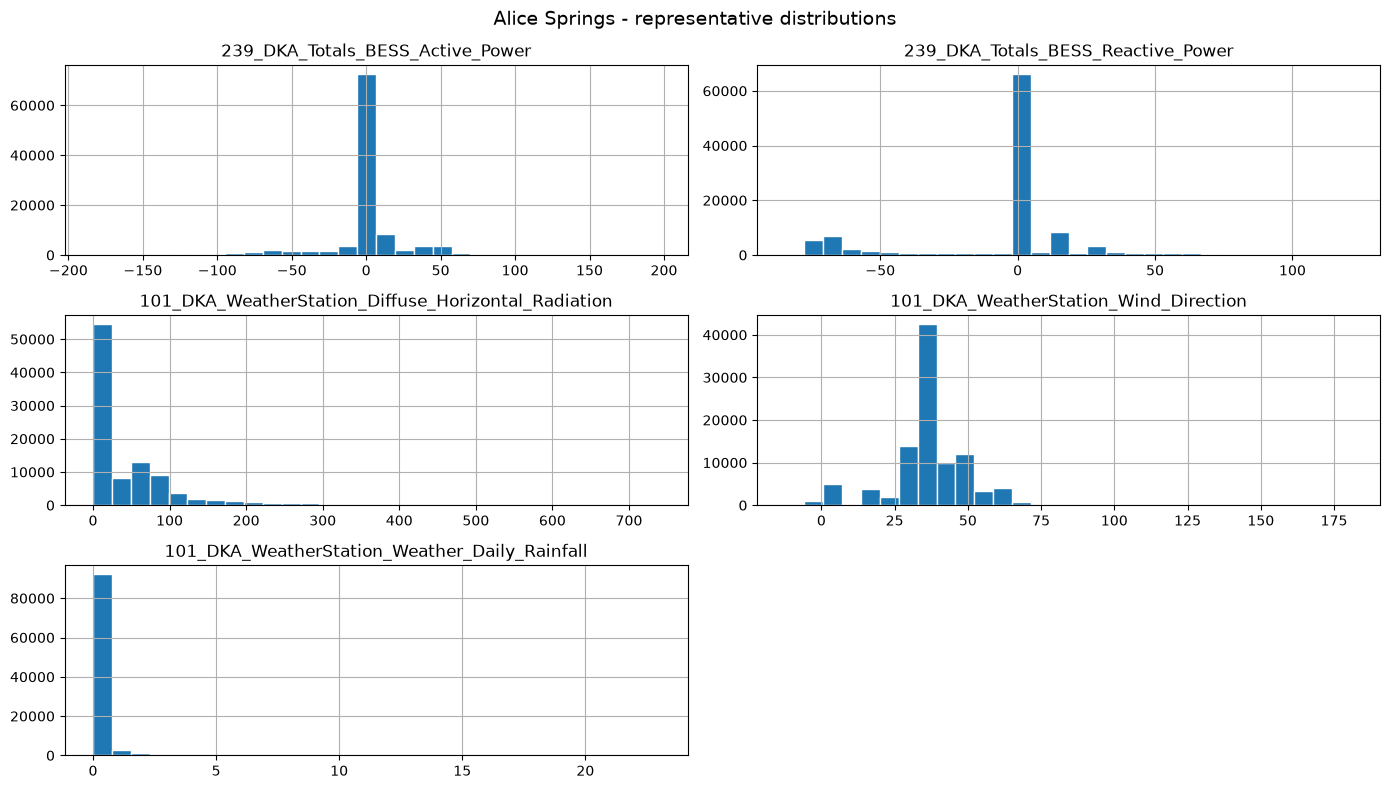

Alice Springs shape: (105391, 210)
Missing cells: 2500580
Representative numeric columns: 5


In [9]:
alice_path = RAW_DIR / "Alice_Springs_2025.csv"
alice_df = pd.read_csv(alice_path, on_bad_lines="skip", low_memory=False)

keywords = [
    "Active_Power",
    "Reactive_Power",
    "Radiation_Global_Horizontal",
    "Diffuse_Horizontal_Radiation",
    "Wind_Direction",
    "Daily_Rainfall",
]

selected_columns = []
for keyword in keywords:
    matches = [
        column for column in alice_df.select_dtypes(include="number")
        if keyword in column and alice_df[column].notna().sum() > 0
    ]
    if matches:
        selected_columns.append(matches[0])

if selected_columns:
    alice_df[selected_columns].hist(
        bins=30,
        figsize=(14, 8),
        edgecolor="white",
    )
    plt.suptitle("Alice Springs - representative distributions", fontsize=14)
    plt.tight_layout()
    plt.show()

print("Alice Springs shape:", alice_df.shape)
print("Missing cells:", int(alice_df.isna().sum().sum()))
print("Representative numeric columns:", len(selected_columns))

## Alice Springs column families

The 210 columns in this dataset are measurements from different energy and weather systems. The table below groups the column names into simple families.

| Family | What the family represents | Main measurements included |
|---|---|---|
| Timestamp | Time of each observation | `timestamp` |
| Battery / BESS | Energy storage system totals | Active, reactive, and apparent power; state of charge |
| PV / Solar | Total electrical output generated by the photovoltaic system | Active, reactive, and apparent power |
| Grid | Electrical exchange with the external grid | Grid active, reactive, and apparent power |
| Site demand | Total electrical demand at the site | Site-demand active, reactive, and apparent power |
| Inverter / solar meters | Measurements from individual PV meters, such as M1 to M20 | Active energy, current, active power, and sometimes performance ratio |
| Phase measurements | Electrical data from phases A, B, or C, including 3-phase and combined-phase meters | Current, voltage-related values, active energy, active power, and performance ratio |
| Master meters | Main site electrical meters | Active energy, current, active power, power factor, voltage, frequency, and voltage THD |
| Weather station | Environmental conditions used to explain solar production | Temperature, humidity, wind speed and direction, rainfall, global radiation, and diffuse radiation |
| Archived measurements | Older or archived meter readings | Mostly QCells/UMG active energy, current, and active power |